# Exercise 9: NetworkX Tutorial

This notebook introduces **NetworkX**, a Python library for building and analyzing graphs (networks).


### Setup
You need: `networkx`

If needed:
```bash
pip install networkx 
```

In [120]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd

print(nx.__version__)

3.6.1


## Graph basics: nodes and edges

A **graph** is a mathematical object made of:
- **Nodes** (aka vertices)
- **Edges** (connections between nodes)

Formally, Nodes are elements of a set, $V$, while edges are a subset of the set product of $V$ with itself. We typically call the resulting graph $G$.

- $V = \{v_1,v_2, \dots, v_n\}$
- $E \subseteq V \times V$ 
- $G = (V,E)$

### Networks 
A **network** is distinct a graph that represents real-world data or phenomenon. I.e., it is a graph with some semantic meaning attached to the vertices and edges. 

- Nodes = people, edges = friendships → social network
- Nodes = cities, edges = roads → transportation network
- Nodes = proteins, edges = interactions → biological network

In practice, the terms graph and network are often used interchangeably, though network usually emphasizes an applied or empirical context.
**Network analysis** is a distinct area within data science and applied mathematics.  
While many real-world systems can be naturally represented as networks, historically:

- Supervised learning methods were difficult to apply directly to relational data
- - Changes is node/edge ordering will change analysis; computing a ''canonical form'' is an open problem
- - - This is closely related to the graph isomorphism problem, which is neither known to be NP-complete nor known to admit a polynomial-time algorithm
- - There are no features to learn, the data is more abstract
- - Size of structure is variable; be it the number of nodes or size of subgraph

- Statistical modeling of networks lagged behind tabular data until the mid-to-late 1990s
- - We needed stronger theory on small world networks, exponential random graphs, and later graph embeddings
- - Now, GNNs are very popular

This has changed substantially in recent years with advances in computation and methodology.


### NetworkX

In this course, we will use **NetworkX**, a Python library for creating, manipulating, and analyzing graphs and networks. Its main advantages are:
- Simple API
- Documentation
- Well-suited for teaching, prototyping, and exploratory analysis

NetworkX prioritizes clarity and flexibility over speed. For very large graphs or performance-critical applications, other Python libraries (e.g., `graph-tool`) may be more appropriate.

NetworkX supports several graph types:

- `nx.Graph()` – undirected graphs  
- `nx.DiGraph()` – directed graphs  
- `nx.MultiGraph()` – undirected graphs with parallel edges  
- `nx.MultiDiGraph()` – directed graphs with parallel edges  

We will mostly focus on general undirected graphs, though there are good use cases for DiGraphs and MultiGraphs.


In [121]:
G = nx.Graph()

# Add nodes
G.add_node("Alice")
G.add_nodes_from(["Bob", "Charlie", "Dina"])

# Add edges
G.add_edge("Alice", "Bob")
G.add_edges_from([
    ("Bob", "Charlie"),
    ("Charlie", "Dina"),
    ("Alice", "Dina"), 
    ("Dina", "Carlos") #Notice Carlos is not yet a node
])

print("Nodes:", list(G.nodes))
print("Edges:", list(G.edges))
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Nodes: ['Alice', 'Bob', 'Charlie', 'Dina', 'Carlos']
Edges: [('Alice', 'Bob'), ('Alice', 'Dina'), ('Bob', 'Charlie'), ('Charlie', 'Dina'), ('Dina', 'Carlos')]
Number of nodes: 5
Number of edges: 5


Graphs in NetworkX rely heavily on *dictionaries*. Each vertex is basically a dictionary with a list of properties, and maintains an adjacency list as well.

In [122]:
for n in G.nodes:
    print(n, "->", list(G.neighbors(n)))

Alice -> ['Bob', 'Dina']
Bob -> ['Alice', 'Charlie']
Charlie -> ['Bob', 'Dina']
Dina -> ['Charlie', 'Alice', 'Carlos']
Carlos -> ['Dina']


We can see this is a dictionary using dict-like indexing. Note that AtlasView is a special property that indicates the node/edge object is read-only. 

In [123]:
G['Alice']


AtlasView({'Bob': {}, 'Dina': {}})

In [124]:
G['Alice']['Bob']

{}

In [125]:
#G['Alice']['Charlie']
"""
---------------------------------------------------------------------------
KeyError                                  Traceback (most recent call last)
Cell In[7], line 1
----> 1 G['Alice']['Charlie']

File ~\AppData\Local\Python\pythoncore-3.15-64\Lib\site-packages\networkx\classes\coreviews.py:54, in AtlasView.__getitem__(self, key)
     53 def __getitem__(self, key):
---> 54     return self._atlas[key]

KeyError: 'Charlie'
"""

"\n---------------------------------------------------------------------------\nKeyError                                  Traceback (most recent call last)\nCell In[7], line 1\n----> 1 G['Alice']['Charlie']\n\nFile ~\\AppData\\Local\\Python\\pythoncore-3.15-64\\Lib\\site-packages\networkx\\classes\\coreviews.py:54, in AtlasView.__getitem__(self, key)\n     53 def __getitem__(self, key):\n---> 54     return self._atlas[key]\n\nKeyError: 'Charlie'\n"

Each node/edge object can contain additional attributes, but to modify them, you must access the objects properly.

In [126]:
G.nodes()['Alice']['birthday'] = "April"

G.nodes()['Alice']

{'birthday': 'April'}

Of course, adding nodes, edges, and attributes can all be done programmatically. 

In [127]:
for v in G.nodes():
    print(v)
    G.nodes()[v]['person'] = True

Alice
Bob
Charlie
Dina
Carlos


In [128]:
#Alternative (nicer) syntax
for v, data in G.nodes(data=True):
    print(v)
    data['person'] = True

Alice
Bob
Charlie
Dina
Carlos


In [129]:
first_names = [
    "Alice",
    "Jamal",
    "Priya",
    "Luca",
    "Sofia",
    "Daniel",
    "Fatima",
    "Noah",
    "Mei",
    "Carlos",
    "Aisha",
    "Tomas",
    "Elena",
    "Marcus",
    "Yuki",
    "Rohan",
    "Isabelle",
    "Ahmed",
    "Hannah",
    "Diego"
]

In [130]:
for name in first_names: 
    G.add_node(name)

#Or, if vertices already in a list
G.add_nodes_from(first_names)


In [131]:
new_edges = [('Alice', 'Bob'), ('Alice', 'Dina'), ('Bob', 'Charlie'), ('Charlie', 'Dina'), ('Dina', 'Carlos')]
G.add_edges_from(new_edges)

In [132]:
G.nodes()

NodeView(('Alice', 'Bob', 'Charlie', 'Dina', 'Carlos', 'Jamal', 'Priya', 'Luca', 'Sofia', 'Daniel', 'Fatima', 'Noah', 'Mei', 'Aisha', 'Tomas', 'Elena', 'Marcus', 'Yuki', 'Rohan', 'Isabelle', 'Ahmed', 'Hannah', 'Diego'))

### Task 1 
- Create a new graph, G (erasing the above graph in memory)
- Add the people's names (from the `first_names` list) as nodes to the graph
- Connect two people with an edge if their names share a letter
- Report the number of nodes and edges in this graph. What can you reason about, if anything, this graph's structure? 

In [133]:
# your code here
G = nx.Graph()

# Add all names as nodes
G.add_nodes_from(first_names)

# Connect two people if their names share at least one letter
for i, name1 in enumerate(first_names):
    for name2 in first_names[i + 1:]:
        if set(name1.lower()) & set(name2.lower()):
            G.add_edge(name1, name2)

# Report the number of nodes and edges
print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

Number of nodes: 20
Number of edges: 173


**todo** your response here

-------- VIPINS ANSWER HERE ---------

The graph contains 20 nodes and 173 edges. It is a very dense, connected graph, meaning that most pairs of people share at least one letter in their names. There are 190 possible edges in a graph with 20 nodes, so 173 edges represent a density of approximately 91%. Some nodes have connections to every other node, while others have fewer connections.

How the code works:
- set(name1.lower()) converts a name into a set of its unique lowercase letters.
- & calculates the intersection of two sets.
- If the intersection is non-empty, the names share at least one letter, so we add an edge.
- first_names[i + 1:] ensures we don't compare a name with itself or repeat comparisons in reverse order.

## Drawing graphs

NetworkX uses Matplotlib for drawing. However, there are some easy shortcuts.

The drawing routines are seperate from the layout routines. This is a design decision in case you want finer control over the layout. 

A layout is an assignment of coordinates to the vertices of the graph (edges are drawn as straight-line segments between them).
There are many layouts built in to the library, for instance:
- `spring_layout` 
- `circular_layout`
- `kamada_kawai_layout`
- `shell_layout`

Note: NetworkX is **not**, a visualization library. GraphViz is an excellent open source graph drawing library with nice Python bindings (also available within NetworkX).

In [134]:
G = nx.Graph()

# Add nodes
G.add_node("Alice")
G.add_nodes_from(["Bob", "Charlie", "Dina"])

# Add edges
G.add_edge("Alice", "Bob")
G.add_edges_from([
    ("Bob", "Charlie"),
    ("Charlie", "Dina"),
    ("Alice", "Dina"), 
    ("Dina", "Carlos") #Notice Carlos is not yet a node
])

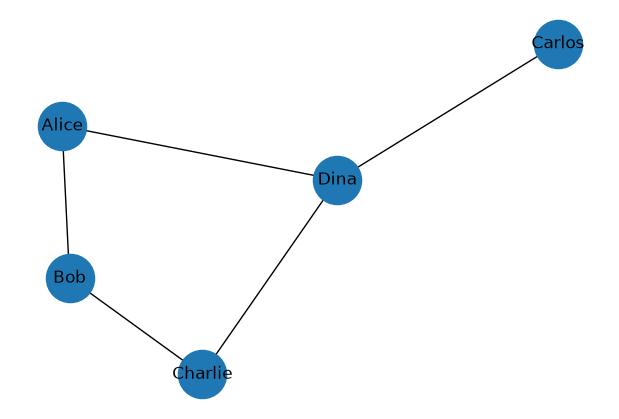

In [135]:
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

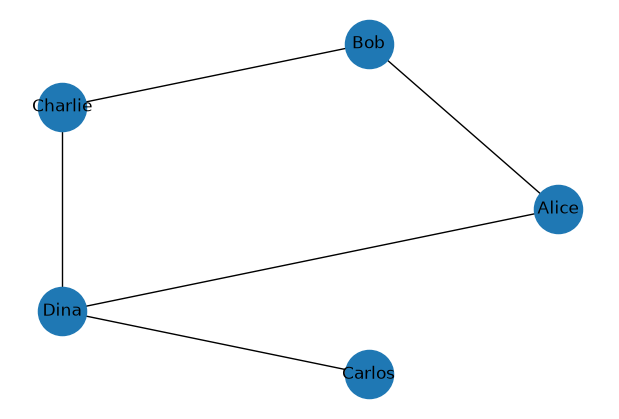

In [136]:
plt.figure(figsize=(6, 4))
pos = nx.circular_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

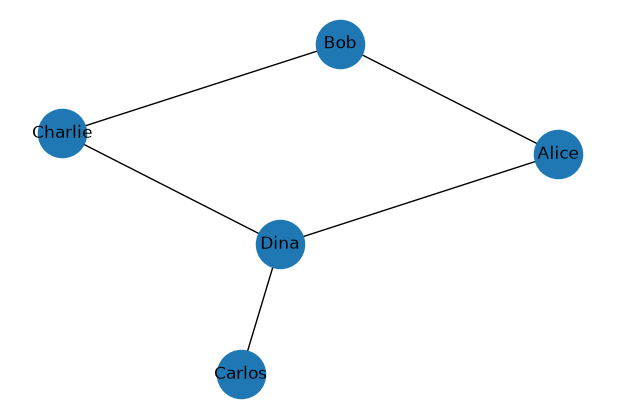

In [137]:
plt.figure(figsize=(6, 4))
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

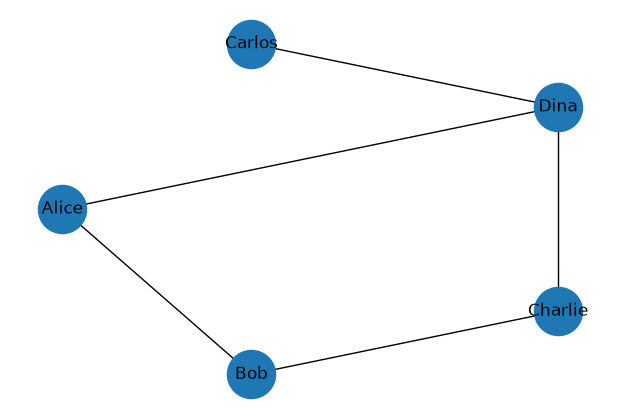

In [138]:
plt.figure(figsize=(6, 4))
pos = nx.shell_layout(G)
nx.draw(G, pos, with_labels=True, node_size=1200)
plt.show()

Each of the NetworkX layout algorithms return a dictionary of numpy arrays (length 2) for the x and y positions. 

In [139]:
pos

{'Alice': array([-1.00000000e+00, -8.74227766e-08]),
 'Bob': array([-0.30901712, -0.95105648]),
 'Charlie': array([ 0.80901724, -0.58778495]),
 'Dina': array([0.809017  , 0.58778524]),
 'Carlos': array([-0.30901742,  0.95105636])}

Network layout is a conceptually simple but technically deep field. Many popular algorithms focus on physical principles, modeling the vertices as particles and edges as springs. Particles repel each other, while springs have a desired length. Simulating this system results in a low-energy configuration which tends to be aesthetically pleasing. 

# Task 2: Visualization 
Finding the right layout algorithm for your graph to get some conceptual understanding of the data is often an iterative process. 
- Load the edge list in sierpinski.txt. You may need to open the file to understand its structure, but is simply a list of edges. 
- Try to guess what the structure of the graph looks like from the list
- Try several layout algorithms to see which gives you good results

In [140]:
# Your code here
# Load the edge list
#G = nx.read_edgelist("sierpinski.txt")

#print("Number of nodes:", G.number_of_nodes())
#print("Number of edges:", G.number_of_edges())

# Try different layouts
#layouts = {
#    "Spring": nx.spring_layout(G, seed=42),
#    "Circular": nx.circular_layout(G),
#    "Kamada-Kawai": nx.kamada_kawai_layout(G),
#    "Shell": nx.shell_layout(G)
#}

#for name, pos in layouts.items():
#    plt.figure(figsize=(6, 6))
#    nx.draw(G, pos, with_labels=True, node_size=100)
#    plt.title(name + " Layout")
#    plt.show()


# ---------------------------------------------------------------------------
# FileNotFoundError                         Traceback (most recent call last)
# Cell In[98], line 3
#     1 # Your code here
#     2 # Load the edge list
# ----> 3 G = nx.read_edgelist("sierpinski.txt")
#     4
#     5 print("Number of nodes:", G.number_of_nodes())
#     6 print("Number of edges:", G.number_of_edges())
#
# File c:\Users\vipin\anaconda3\Lib\site-packages\networkx\utils\decorators.py:784, in argmap.__call__.<locals>.func(_argmap__wrapper, *args, **kwargs)
#     783 if func(*args, __wrapper=None, **kwargs):
#     784     return argmap._lazy_compile(__wrapper)(*args, **kwargs)
#
# File <class 'networkx.utils.decorators.argmap'> compilation 72:3, in argmap_read_edgelist_67(path, comments, delimiter, create_using, nodetype, data, edgetype, encoding, backend, **backend_kwargs)
#     1 import bz2
#
# File c:\Users\vipin\anaconda3\Lib\site-packages\networkx\utils\decorators.py:194, in open_file.<locals>._open_file(path)
#   190 else:
#   191     # could be None, or a file handle, in which case the algorithm will deal with it
#   192     return path, lambda: None
# ----> 194 fobj = _dispatch_dict[ext](path, mode=mode)
#   195 return fobj, lambda: fobj.close()
#
# FileNotFoundError: [Errno 2] No such file or directory: 'sierpinski.txt'


## Simple analysis: Degrees

The degree of a vertex in a graph is the number of incident edges (i.e. the number of neighbors). It turns out, that looking at this statistic across the graph is actually pretty informative. 


In [141]:
#This is a popular social network for analysis, a co-occurance network from the novel Les Miserable.
G = nx.read_gml("lesmis.gml")

In [142]:
degree = nx.degree(G)
for deg in degree: 
    print(deg)

('Myriel', 10)
('Napoleon', 1)
('MlleBaptistine', 3)
('MmeMagloire', 3)
('CountessDeLo', 1)
('Geborand', 1)
('Champtercier', 1)
('Cravatte', 1)
('Count', 1)
('OldMan', 1)
('Labarre', 1)
('Valjean', 36)
('Marguerite', 2)
('MmeDeR', 1)
('Isabeau', 1)
('Gervais', 1)
('Tholomyes', 9)
('Listolier', 7)
('Fameuil', 7)
('Blacheville', 7)
('Favourite', 7)
('Dahlia', 7)
('Zephine', 7)
('Fantine', 15)
('MmeThenardier', 11)
('Thenardier', 16)
('Cosette', 11)
('Javert', 17)
('Fauchelevent', 4)
('Bamatabois', 8)
('Perpetue', 2)
('Simplice', 4)
('Scaufflaire', 1)
('Woman1', 2)
('Judge', 6)
('Champmathieu', 6)
('Brevet', 6)
('Chenildieu', 6)
('Cochepaille', 6)
('Pontmercy', 3)
('Boulatruelle', 1)
('Eponine', 11)
('Anzelma', 3)
('Woman2', 3)
('MotherInnocent', 2)
('Gribier', 1)
('Jondrette', 1)
('MmeBurgon', 2)
('Gavroche', 22)
('Gillenormand', 7)
('Magnon', 2)
('MlleGillenormand', 7)
('MmePontmercy', 2)
('MlleVaubois', 1)
('LtGillenormand', 4)
('Marius', 19)
('BaronessT', 2)
('Mabeuf', 11)
('Enjolras'

A common visualization scheme is to scale the size of a vertex based on it's degree. Let's take a look.

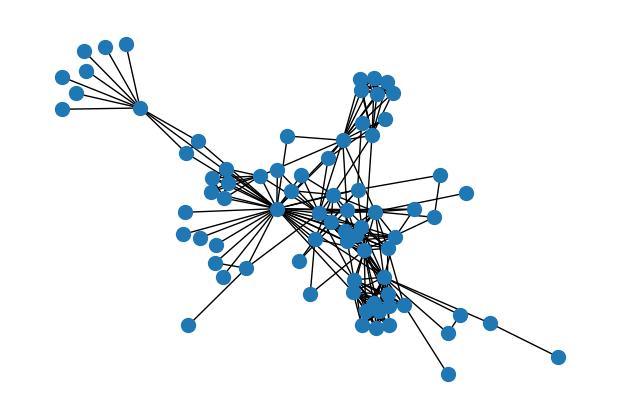

In [143]:
plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=False, node_size=100)
plt.show()

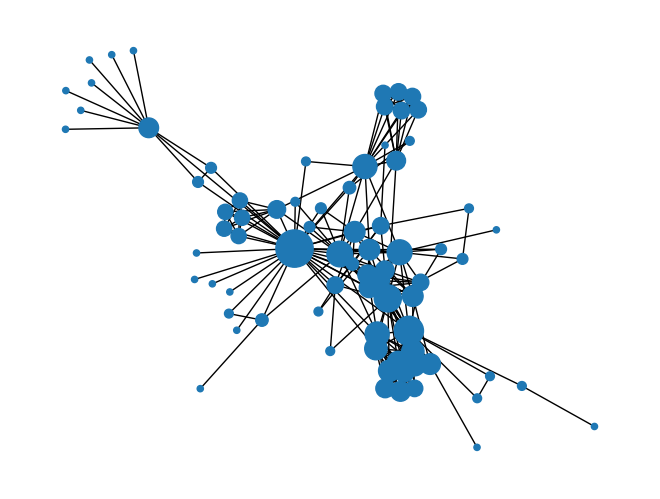

In [144]:
sizes = [degree[v] * 20 for v in G.nodes()]

# plt.figure(figsize=(6, 4))
pos = nx.spring_layout(G, seed=42)
nx.draw(G, pos, with_labels=False, node_size=sizes)
plt.show()

Of course, with NetworkX's limited visualization options, a degree histogram is more informative. 

<BarContainer object of 37 artists>

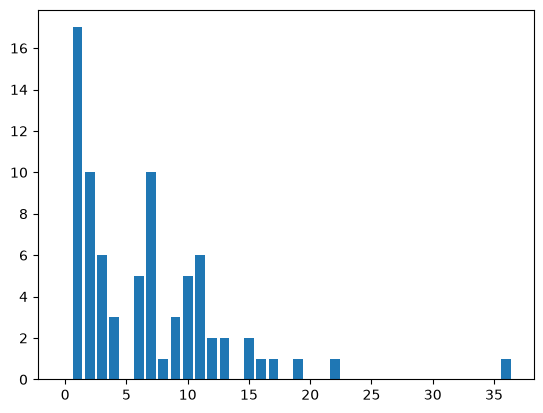

In [145]:
counts = nx.degree_histogram(G)
bins = range(len(counts))
plt.bar(bins, counts)

What does this tell us about the graph? 

In [146]:
print(list(G.nodes))

['Myriel', 'Napoleon', 'MlleBaptistine', 'MmeMagloire', 'CountessDeLo', 'Geborand', 'Champtercier', 'Cravatte', 'Count', 'OldMan', 'Labarre', 'Valjean', 'Marguerite', 'MmeDeR', 'Isabeau', 'Gervais', 'Tholomyes', 'Listolier', 'Fameuil', 'Blacheville', 'Favourite', 'Dahlia', 'Zephine', 'Fantine', 'MmeThenardier', 'Thenardier', 'Cosette', 'Javert', 'Fauchelevent', 'Bamatabois', 'Perpetue', 'Simplice', 'Scaufflaire', 'Woman1', 'Judge', 'Champmathieu', 'Brevet', 'Chenildieu', 'Cochepaille', 'Pontmercy', 'Boulatruelle', 'Eponine', 'Anzelma', 'Woman2', 'MotherInnocent', 'Gribier', 'Jondrette', 'MmeBurgon', 'Gavroche', 'Gillenormand', 'Magnon', 'MlleGillenormand', 'MmePontmercy', 'MlleVaubois', 'LtGillenormand', 'Marius', 'BaronessT', 'Mabeuf', 'Enjolras', 'Combeferre', 'Prouvaire', 'Feuilly', 'Courfeyrac', 'Bahorel', 'Bossuet', 'Joly', 'Grantaire', 'MotherPlutarch', 'Gueulemer', 'Babet', 'Claquesous', 'Montparnasse', 'Toussaint', 'Child1', 'Child2', 'Brujon', 'MmeHucheloup']


### Other analysis
NetworkX contains most classical graph algorithms if they are needed for preprocessing.

In [147]:
print(nx.shortest_path(G, "Myriel", "Napoleon"))
print("Length:", nx.shortest_path_length(G, "Myriel", "Napoleon"))

['Myriel', 'Napoleon']
Length: 1


## Reading and writing data
Unfortunately, there is still no standard format for network data. Fortunately, NetworkX can read most of them you come across in practice. 

In [148]:
G = nx.read_gml("lesmis.gml")

Typically, you will write to a format you need the data in, or otherwise most convienient. JSON is a nice, human readable format.

In [149]:
import json
jsdata = nx.node_link.node_link_data(G)
with open("jsdata.json", 'w') as fdata:
    json.dump(jsdata,fdata,indent=4)


## Working from tabular data 

A common workflow:
1. You have a table of edges (`source`, `target`, maybe `weight`)
2. Convert it into a graph


In [150]:
edges_df = pd.DataFrame({
    "source": ["A", "A", "B", "C", "D"],
    "target": ["B", "C", "C", "D", "A"],
    "weight": [3, 1, 2, 4, 5]
})
edges_df

,source,target,weight
0,A,B,3
1,A,C,1
2,B,C,2
3,C,D,4
4,D,A,5


Edges with data:
[('A', 'B', {'weight': 3}), ('A', 'C', {'weight': 1}), ('A', 'D', {'weight': 5}), ('B', 'C', {'weight': 2}), ('C', 'D', {'weight': 4})]


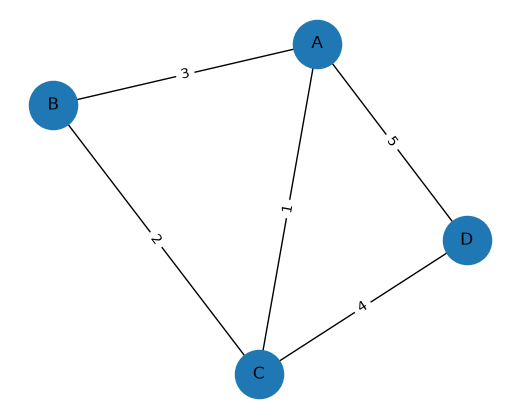

In [151]:
H = nx.from_pandas_edgelist(edges_df, source="source", target="target", edge_attr=True, create_using=nx.Graph())

print("Edges with data:")
print(list(H.edges(data=True)))

plt.figure(figsize=(5, 4))
pos = nx.spring_layout(H, seed=1)
nx.draw(H, pos, with_labels=True, node_size=1200)
nx.draw_networkx_edge_labels(H, pos, edge_labels=nx.get_edge_attributes(H, "weight"))
plt.show()

# Task 3: Real data
Of course, real data is likely not nicely specified with a "source" and "target" attribute. 

Included in this directory is `imdb_top250.csv`, which is a dataset that consists of the 250 highest ranked movies from IMDB. Several graphs could be derived from this data, but a natural one is described as follows: 
- Every movie defines a vertex 
- Two movies share an edge if they also share a costar (i.e. an overlap in their actor list).

Constructing a graph in this fashion is closer to an art than a science. We want to do it in a consistent, but parameterized way so that we can threshold and filter the data to obtain an ''analyzable'' output. Therefore your task is to write a function which 
- Constructs the graph described above
- Has a parameter, $k$, for which an edge is only added between movies if they share $k$ costars
- Has a parameter, `num_stars`, which controls how many of the actors/actresses in the list are looked at (they are listed in order of credits).

Afterwards, perform the basic analysis of visualization and analyzing degree distributions described earlier. What is the structure of the graph? Are there different components? Are there hub vertices? Save the graph to file for later use. 

In [152]:
# your code here

# Build the graph


import itertools

def create_movie_graph(df, k=1, num_stars=10):
    G = nx.Graph()

    # Add each movie as a node
    for _, row in df.iterrows():
        G.add_node(
            row["tconst"],
            title=row["primaryTitle"]
        )

    # Extract the actors for each movie
    movie_actors = {}

    for _, row in df.iterrows():
        actors = str(row["actors_top10"]).split(",")
        actors = [actor.strip() for actor in actors[:num_stars]]
        movie_actors[row["tconst"]] = set(actors)

    # Compare every pair of movies
    for movie1, movie2 in itertools.combinations(movie_actors, 2):
        shared_actors = movie_actors[movie1] & movie_actors[movie2]

        if len(shared_actors) >= k:
            G.add_edge(movie1, movie2)

    return G

In [153]:
# Create graph and do analysis

# Load the dataset
df = pd.read_csv("imdb_top100.csv")

# Create the graph
G = create_movie_graph(df, k=2, num_stars=10)

print("Number of nodes:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

# Connected components
components = list(nx.connected_components(G))

print("Number of components:", len(components))
print("Component sizes:", sorted(
    [len(c) for c in components],
    reverse=True
))

# Identify the movies with the highest degree
degrees = dict(G.degree())

top_movies = sorted(
    degrees.items(),
    key=lambda x: x[1],
    reverse=True
)[:10]

print("\nTop 10 movies by degree:")

for movie, degree in top_movies:
    print(G.nodes[movie]["title"], ":", degree)

Number of nodes: 100
Number of edges: 21
Number of components: 83
Component sizes: [4, 3, 3, 3, 3, 2, 2, 2, 2, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Top 10 movies by degree:
The Dark Knight Rises : 3
The Godfather : 2
The Dark Knight : 2
The Lord of the Rings: The Return of the King : 2
The Godfather Part II : 2
The Lord of the Rings: The Fellowship of the Ring : 2
The Lord of the Rings: The Two Towers : 2
Star Wars: Episode V - The Empire Strikes Back : 2
Star Wars: Episode IV - A New Hope : 2
The Prestige : 2


Here, k=2 means two movies must share at least two actors to be connected.

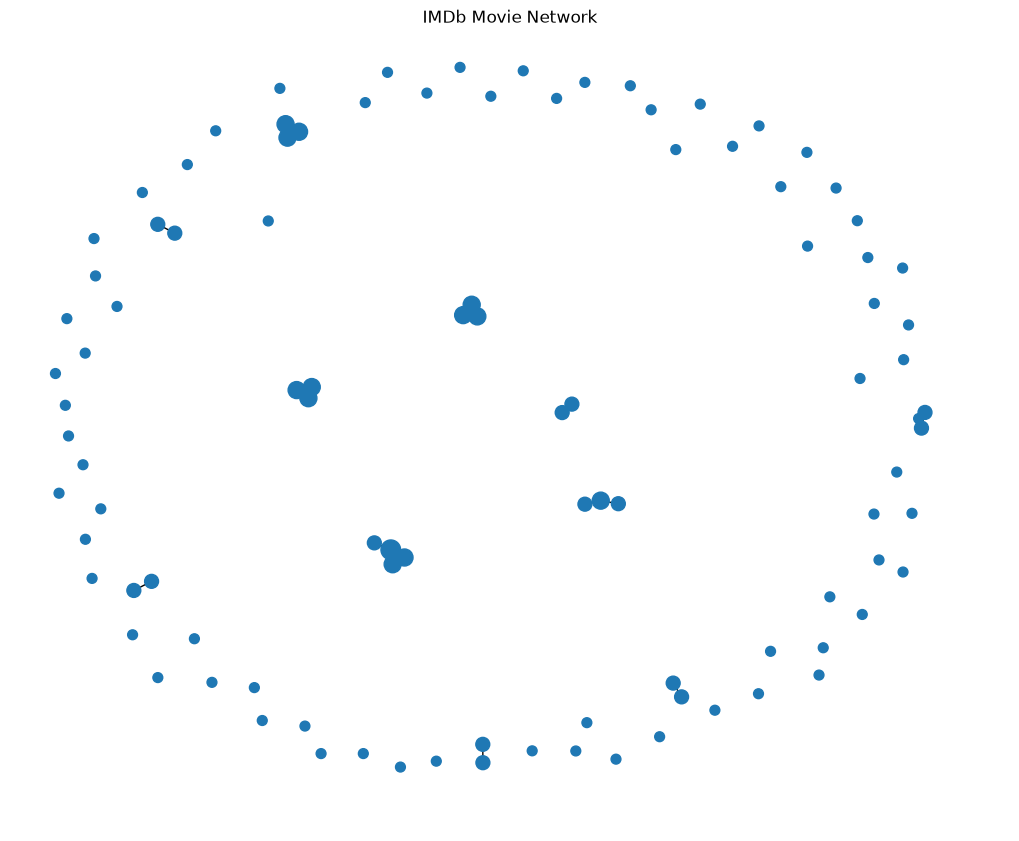

In [154]:
# Visualize the graph
plt.figure(figsize=(10, 8))

pos = nx.spring_layout(G, seed=42)

# Scale node sizes according to their degree
sizes = [G.degree(v) * 50 + 50 for v in G.nodes()]

nx.draw(
    G,
    pos,
    with_labels=False,
    node_size=sizes
)

plt.title("IMDb Movie Network")
plt.show()

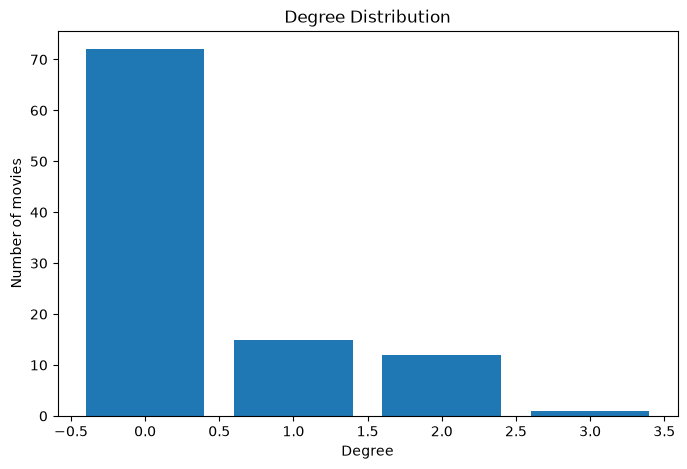

In [155]:
# Plot the degree distribution
degree_counts = nx.degree_histogram(G)

plt.figure(figsize=(8, 5))
plt.bar(range(len(degree_counts)), degree_counts)

plt.xlabel("Degree")
plt.ylabel("Number of movies")
plt.title("Degree Distribution")
plt.show()

In [156]:
# Save the graph to a GML file
nx.write_gml(G, "imdb_movie_network.gml")

# later we can load again using
# G = nx.read_gml("imdb_movie_network.gml")